# 21 Tagesmonitor mit CUSUM

## Worum es in diesem Notebook geht

**Frage**
- läuft die Station schlechter als früher? --> jede Station gegen sich selbst, jeden Tag
- Gegenstück zum Netzvergleich (Station gegen alle anderen, je Kernwinter)
- Idee aus NB 17 (Normalverhaltensmodell), ersetzt den Fensteralarm aus NB 14

**Zwei Kanäle je Heiztag** (Tagesmittel unter 15 °C, aus den Zählerständen um Mitternacht)
- Abkühlung in kWh/m³ (≈ Spreizung × 1,16) und Wassermenge (Tagesvolumen)

**Lernjahr**
- im ersten Jahr einer Station wird gelernt, welcher Wert bei welcher Außentemperatur normal ist
- endet spätestens 14 Tage vor der ersten Begehung, mind. 60 Heiztage und 8 K Temperaturspanne

**CUSUM = Konto für Abweichungen**
- z = (heute − erwartet aus dem Lernjahr) / übliche Schwankung der Station
- Konto: jeden Tag + z − 0,5, nie unter 0, Alarm wenn Konto > 5; zwei Konten: über und unter der Erwartung
  --> einzelner Ausreißer verpufft, dauerhafte Verschiebung summiert sich (z = 1 --> Alarm nach ~11 Tagen, z = 2 --> nach 4 Tagen)
- Alarm mit Richtung: schlechter (Abkühlung sinkt oder Wasser steigt) oder besser
- neuer Alarm in dieselbe Richtung erst, wenn das Konto zwischendurch bei 0 war --> dauerhafte Änderung meldet nur einmal

**Grenze**
- gelernt wird das Übliche, nicht das Gute --> war die Station im Lernjahr schon kaputt, gilt kaputt als normal (68956351)
  --> deshalb braucht es den Netzvergleich daneben

**Was ins Ergebnis eingeht**
- Alarm "schlechter" in der Heizperiode (Okt–Apr) + im Netz auffällig --> Priorität hoch, nur eins davon --> mittel
- Abkühlung bei 5 °C nur als Info in der Statuszeile, nicht im Score

**Prüfungen in diesem Notebook**
- hilft die Temperatur bei der Vorhersage? (Abschnitt 4)
- trifft der CUSUM Begehungen häufiger als Stationen ohne Begehung am selben Datum? (Abschnitt 7)
- verändert die Begehung die Station messbar? (Abschnitt 8)
- findet eine einfache Größe dieselben schlechten Stationen wie der Netzvergleich? (Abschnitt 9)

- Stundenreihen aus Notebook 00; Logik in `src/tagesmonitor.py`, Einbindung in `src/stationsblatt.py`, Doku in `docs/kennlinien-monitor.md`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import stationsblatt as bl
from src import tagesmonitor as tm

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

BEISPIEL = 68956351

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"])
r = erg["tagesmonitor"]
termine = erg["termine"]
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")

93 Stundenreihen aus NB 00, gerechnet in 237 s


## Tageswerte und Ausschlüsse

**2 · Tageswerte und Ausschlüsse**

**Welche Daten der Tagesmonitor nutzt**
- nur Zählerstände (Energie, Volumen) + Tagesmittel Außentemperatur (DWD)
- Stundenwerte (Durchfluss, Leistung) nur für Nebensachen (Messstunden zählen, Prüfung "Zähler steht"), Rücklauf und Vorlauf gar nicht
  --> warum: Tagesverbrauch aus Zählerständen exakt (Stundenwerte sind Momentaufnahmen, Check D2), auch in der Tageswert-Phase vorhanden, Tageswert glättet Spitzen
  --> was fehlt: Nachtdurchfluss, Takten, Tagesgang, Rücklauf/Vorlauf einzeln (kWh/m³ ≈ mittlere Spreizung × 1,16)
- Stundenwerte gehen im Modell nicht verloren: Netzvergleich (Kennlinie, Spreizung, Rücklauf > 50 °C) nutzt sie
- Lücke Rücklauf/Nachtdurchfluss deckt Dominiks LSTM-Wächter (NB 21) ab --> mögliche Ergänzung

**Tageswert**
- nur 2 Zählerstände je Tag nötig: Stand um Mitternacht am Anfang und am Ende des Tages
  --> Zähler zählen fortlaufend (wie ein Kilometerzähler) --> Differenz = Verbrauch der ganzen 24 h
- ±2 h = Toleranz, falls kein Stand genau um 0 Uhr da ist (nächster Stand zwischen 22 und 2 Uhr, auf 24 h hochgerechnet)
- Tageswert-Phase (bis Ende 2022, 1 Wert/Tag um 23 Uhr): Stand 23 Uhr liegt in der Toleranz --> voller Tagesverbrauch (23–23 statt 0–24 Uhr)
  --> für den Tagesmonitor reicht 1 Wert/Tag
  --> im Netzvergleich nicht: Kennlinie braucht viele Stundenpunkte --> 21/22 fällt dort raus
- Abkühlung = Energie / Volumen (kWh/m³), Wassermenge = Volumen (im Modell als Logarithmus)
- Heiztag = Tagesmittel unter 15 °C
- Regeln aus NB 06 übernommen

**Ausschlüsse** (kein Tag gelöscht, Grund steht dran, ein Tag kann mehrere Gründe haben)
- kein_zaehlerstand 239 Tage (kein Stand ±2 h um Mitternacht, fast alle Stationen, meist erster/letzter Tag der Reihe)
- ruecksprung 3 (Zählerstand sinkt)
- zaehler_steht 24 (Volumen 0 trotz Durchfluss ≥ 20 l/h bzw. Energie 0 trotz Leistung ≥ 1 kW), nach_stillstand 24 (Folgetag, Zähler holt auf)
- wenig_energie 7.317 (unter 5 kWh am Tag, Sommer/Leerstand)
- unplausibel 19 (über 70 kWh/m³ ≈ 60 K Spreizung, physikalisch kaum möglich)
- ohne_wetter 42 (kein Tagesmittel der Temperatur, unter 20 Wetterstunden)
- wenig_stunden 16.045 (unter 12 Messstunden) --> ignoriert: Tageswert-Phase hat nur 1 Wert/Tag, Zählerstand reicht
  --> sonst fehlten die frühen Jahre, in denen oft das Lernjahr liegt

**Ergebnis**
- 85.983 Stationstage (Tage mit mind. einer Durchflussmessung) --> 78.350 nutzbar (91 %) --> 55.746 nutzbare Heiztage
  --> nur mit diesen Heiztagen rechnet der Tagesmonitor


In [2]:
tage = r["tage"]
print(f"{len(tage)} Stationstage, davon {int(tage['nutzbar'].sum())} nutzbar, "
      f"{len(r['modelltage'])} nutzbare Heiztage")
r["ausschluss"]

85983 Stationstage, davon 78350 nutzbar, 55746 nutzbare Heiztage


,grund,tage,stationen,ignoriert
0,kein_zaehlerstand,239,93,False
1,ruecksprung,3,1,False
2,zaehler_steht,24,2,False
3,nach_stillstand,24,2,False
4,wenig_energie,7317,52,False
5,unplausibel,19,8,False
6,wenig_stunden,16045,69,True
7,ohne_wetter,42,42,False


## Referenzjahr je Station

**3 · Referenzjahr je Station (= Lernjahr)**

**Regeln**
- Start = erster nutzbarer Heiztag, Dauer 1 Jahr (365 Kalendertage)
- Begehung im Lernjahr --> endet 14 Tage vor der ersten Begehung
  --> Lernjahr = Zustand vor dem Eingriff, Prüffenster des Monitors beginnt 7 Tage vor dem Termin
- Überwachung nur mit mind. 60 Heiztagen, mind. 8 K Temperaturspanne (sonst keine Temperaturabhängigkeit lernbar) und Tagen nach dem Lernjahr

**Ergebnis**
- 89 Stationen überwacht, 4 nicht (keine Tage nach dem Lernjahr):
  - 80912191, 81019433, 81050517: Daten erst ab 09/12-2024, Lernjahr würde nach Datenende (07/2025) enden
  - 80912165: Lernjahr endet vor der Begehung, danach keine nutzbaren Heiztage
- Ende nach 1 Jahr: 72 Stationen (Median 230 Lerntage, 20 K Spanne, 504 überwachte Heiztage)
- Ende vor Begehung: 21 Stationen (Median 209 Lerntage, 21 K, nur 240 überwachte Heiztage)

**Zwei Gruppen nach Datenbeginn (NB 00)**
- 43 Stationen ab 11/2021 --> Lernjahr 11/2021–11/2022, lange Überwachung
- 43 Stationen erst ab 09–11/2023 --> Lernjahr Winter 2023/24, oft gekürzt durch Begehung Herbst 2024 --> Überwachung praktisch erst ab der Begehung
- 68956351: Lernjahr 02.11.2021–02.11.2022 (234 Heiztage, 20 K), 645 überwachte Heiztage, Ventil im Lernjahr schon offen

**Was gelernt wird**
- Abkühlung: robuste Gerade (Theil-Sen) über Tagesmitteltemperatur
- Wassermenge: Median je 2-K-Temperaturklasse (mind. 8 Tage je Klasse), weil nicht linear (warme Tage fast nur Warmwasser)
- je Station übliche Schwankung + Faktor für träge Stationen --> Grundlage für den CUSUM


In [3]:
ref = r["referenz"]
display(ref["status"].value_counts().rename("Stationen").to_frame())
display(ref.groupby("ende_grund")[["ref_tage", "ref_spanne_k",
                                   "ueberwachte_tage"]].median().round(1))

,Stationen
status,
ok,89
keine Tage nach der Referenz,4


,ref_tage,ref_spanne_k,ueberwachte_tage
ende_grund,,,
ein Jahr,230.5,20.0,504.5
vor Begehung,209.0,21.0,240.0


## Hilft die Temperatur überhaupt?

**4 · Hilft die Temperatur überhaupt?**

**Test**
- gelernte Kurve (Wert bei dieser Außentemperatur) gegen Konstante (Median des Lernjahrs, ohne Temperatur)
- auf ungesehenen Tagen: erste 120 Heiztage nach dem Lernjahr, bis 7 Tage vor der nächsten Begehung, mind. 20 Tage
- Fehler = mittlere absolute Abweichung; Skill = 1 − Fehler(Kurve) / Fehler(Median)
  --> 1 = perfekt, 0,28 = 28 % weniger Fehler, 0 = Temperatur bringt nichts, negativ = Kurve schlechter als Median

**Ergebnis** (67 Stationen; Lernjahr kurz vor Begehung --> zu wenige Prüftage)
- Wassermenge: Skill im Median 0,28, bei 84 % positiv --> Temperatur hilft klar (kalt = mehr Wasser)
- Abkühlung: Skill im Median 0,01, nur 54 % positiv --> Temperatur hilft kaum
  --> im Winter hängt kWh/m³ kaum von der Außentemperatur ab, Kurve ≈ Konstante
  --> bei einigen Stationen Kurve sogar schlechter als der Median (bis −2,2): Steigung aus dem Lernjahr passt nicht aufs nächste Jahr
- für den CUSUM reicht eine stabile, fast konstante Erwartung (Ivelinas Lesart), aber das Wetter wird beim Abkühlungskanal kaum herausgerechnet

**Kälteeinbrüche und Fehlalarme**
- Kälteeinbruch (z. B. 09.–12.12.2022: 3,4 --> −3,7 °C), Netz-Vorlauf bleibt gleich (73,7 --> 73,8 °C)
  --> Häuser brauchen mehr Wärme --> Ventile öffnen --> mehr Wasser --> kürzer im Wärmetauscher --> Rücklauf steigt, kWh/m³ sinkt
  --> physikalisch normal, kein Hausfehler
- Tagesmonitor meldet trotzdem "schlechter":
  - Abkühlung: gelernte Kurve ≈ Konstante --> Abfall bei Kälte nicht erwartet
  - Wassermenge: kälter als im Lernjahr --> Kurve bleibt beim kältesten gelernten Wert stehen --> Erwartung zu niedrig
  - Tagesmittel desselben Tages, Gebäude reagieren verzögert (Speichermasse)
  --> mehrere Tage gleiche Abweichung = genau das, was der CUSUM aufsummiert
- Schwelle h: h = 5 --> schon 4–6 Tage Kälte können alarmieren; h = 8 --> ~1/3 weniger Alarme, aber echte Änderungen später gemeldet
  --> Schwelle macht träger, nicht wetterfest

**Umgang im Modell (NB 24)**
- viele gleichzeitige Alarme (±3 Tage, mehr als zufällig) --> Netzereignis --> erst Wetter/Netz prüfen, Priorität bleibt
- unser Lauf: 1 Welle 09.–12.12.2022 bei 12 von 40 Stationen
- an Tagen mit ≥ 5 K Abkühlung binnen einer Woche gut doppelt so viele Verschlechterungen (8,3 % gegen 3,8 % der Stationen)

**Mögliche Lösung**
- Temperatur der letzten 2–3 Tage gemittelt oder 1 Tag verzögert (Gebäudeträgheit)
- Kurve über die kälteste gelernte Temperatur hinaus fortschreiben
- Vorlauf hilft beim Kälteeinbruch nicht (blieb konstant), nur bei Netz-Änderungen
  --> z. B. Nov. 2024: Vorlauf 70,2 --> 72,4 °C bei allen Stationen gleichzeitig, zusammen mit Kälte und 12 Begehungen nicht trennbar
- Dominiks LSTM lernt die Verzögerung über die Vorgeschichte der letzten Woche


,count,mean,std,min,25%,50%,75%,max
kanal,,,,,,,,
kwh_pro_m3,67.0,-0.01,0.40,-2.22,-0.15,0.01,0.23,0.54
log_volumen,67.0,0.25,0.24,-0.49,0.13,0.28,0.39,0.70


,Anteil Skill > 0
kanal,
kwh_pro_m3,0.54
log_volumen,0.84


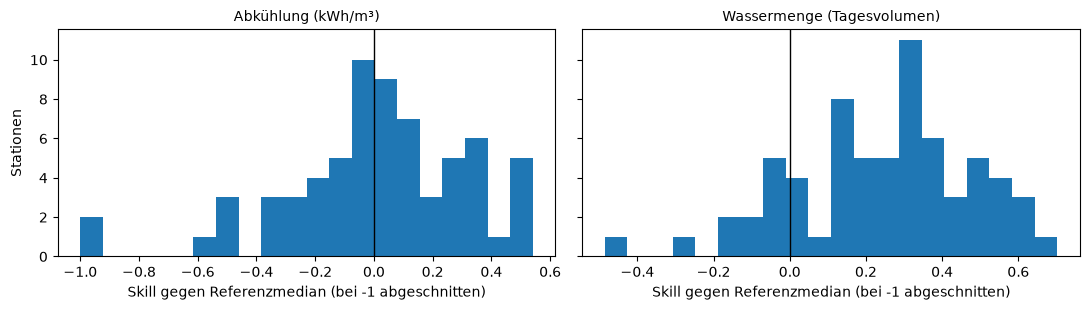

In [4]:
g = tm.guete(r["modelltage"], ref, r["modelle"], termine)
display(g.groupby("kanal")["skill"].describe().round(2))
display(g.groupby("kanal")["skill"].apply(lambda s: (s > 0).mean())
        .rename("Anteil Skill > 0").round(2).to_frame())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, (kanal, titel) in zip(ax, tm.KANAELE.items()):
    s = g.loc[g["kanal"] == kanal, "skill"].clip(-1, 1)
    a.hist(s, bins=20, color="C0")
    a.axvline(0, color="k", lw=1)
    a.set_title(titel, fontsize=10)
    a.set_xlabel("Skill gegen Referenzmedian (bei -1 abgeschnitten)")
ax[0].set_ylabel("Stationen")
plt.tight_layout()
plt.show()

- Für die Wassermenge hilft die Temperatur deutlich, für die Abkühlung in kWh/m³ im Median nicht; dort ist die Kennlinie im Winter fast eine Konstante. Dem CUSUM reicht das als stabile Erwartung.

## Beispiel 68956351

- Die Station mit dem drei Jahre offenen Ventil. Dritte Zeile im Stationsblatt: CUSUM-Konten beider Kanäle, grau das Referenzjahr, rote Linie die Reparatur.
- `richtung` in der Alarmtabelle: bei kWh/m³ heißt 1 mehr Abkühlung (besser), bei der Wassermenge mehr Wasser (schlechter).

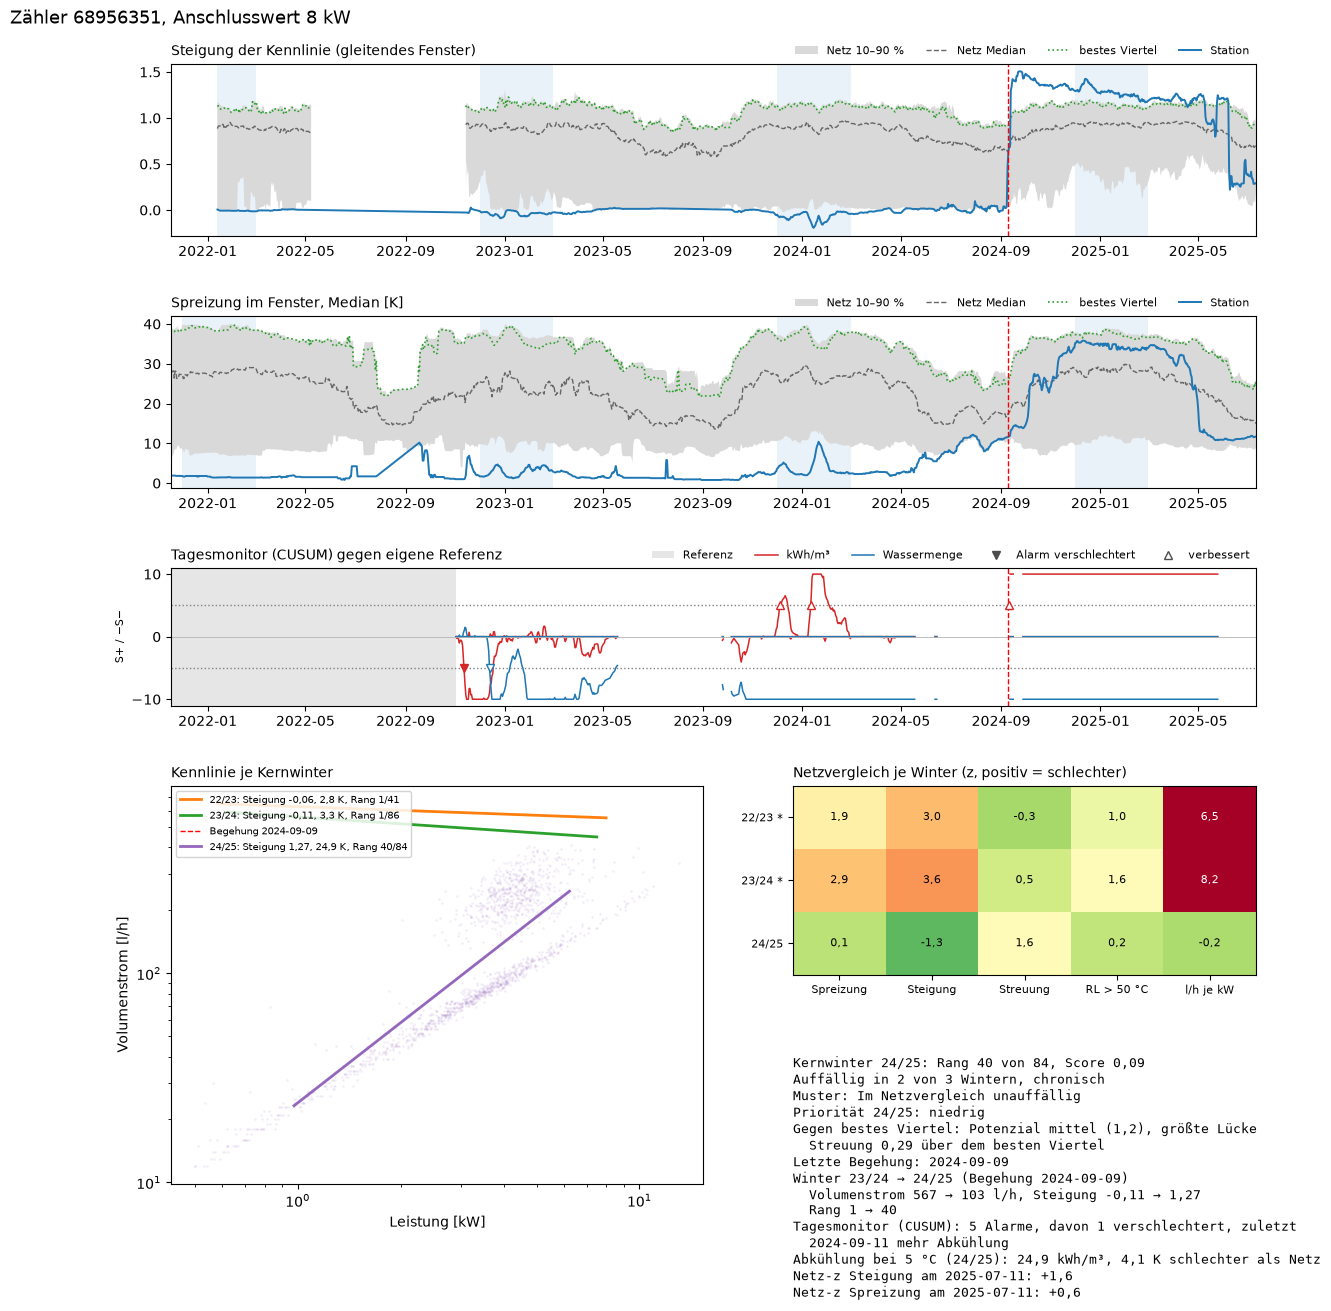

,meter,kanal,datum,richtung,beginn
133,68956351,kwh_pro_m3,2022-11-12,-1,2022-11-03
134,68956351,kwh_pro_m3,2023-12-05,1,2023-11-29
135,68956351,kwh_pro_m3,2024-01-12,1,2024-01-08
136,68956351,kwh_pro_m3,2024-09-11,1,2024-09-11
137,68956351,log_volumen,2022-12-14,-1,2022-12-09


In [5]:
fig = bl.zeichne_stationsblatt(BEISPIEL, erg)
plt.show()
display(r["alarme"][r["alarme"]["meter"] == BEISPIEL])

**5 · Beispiel 68956351**

**Bild:** 3. Zeile = CUSUM-Konten (grau Lernjahr, rot Abkühlung, blau Wassermenge, ▼ schlechter, △ besser, rote Linie Reparatur)
- richtung 1 = Konto nach oben: Abkühlung besser, Wassermenge schlechter; −1 umgekehrt

**Die 5 Alarme**
- 12.11.2022 Abkühlung schlechter (Beginn 03.11., direkt nach Lernjahr-Ende) --> kühlt weniger ab als im Lernjahr, fällt mit Ende der Tageswert-Phase zusammen, Ursache unsicher
- 14.12.2022 Wassermenge besser (Beginn 09.12. = Kälteeinbruch) --> bei Kälte mehr Wasser erwartet, offenes Ventil liefert schon fast das Maximum --> kein echter Erfolg
- 05.12.2023 und 12.01.2024 Abkühlung besser --> Winter 23/24 etwas besser als das Lernjahr, Ventil aber noch offen (Netz-Rang 1)
- 11.09.2024 Abkühlung besser, 2 Tage nach der Reparatur (~5 --> ~25 kWh/m³) --> der echte Erfolg

**Was man daran lernt**
- Alarm = anders als im Lernjahr, nicht kaputt/repariert --> 3 von 4 "besser"-Alarmen mit noch offenem Ventil
- Fehler selbst nie gemeldet: Lernjahr = Zustand mit offenem Ventil --> nur der Netzvergleich zeigt ihn (Rang 1 in 22/23 und 23/24)
- Reparatur nur über die Abkühlung gemeldet: Wasser-Konto hängt seit Dez. 2022 am Deckel (−10), neuer Alarm erst nach Konto = 0
- Priorität: 22/23 hoch (auffällig + Alarm schlechter Nov. 2022), 23/24 mittel (nur besser-Alarme), 24/25 niedrig


## Alarmlast

**6 · Alarmlast**

**Was gemessen wird**
- wie viele Alarme der Tagesmonitor erzeugt = Arbeit, wenn man jeden prüft
- je Station und normiert auf 100 überwachte Heiztage (sonst hätten lang überwachte Stationen automatisch mehr)

**Ergebnis**
- 491 Alarme bei 84 von 89 Stationen, nur 5 ohne Alarm
- je Station Median 4 (mittlere 50 %: 2–8, max 20), 17 Stationen mit ≥ 10
- Median 1,2 je 100 Heiztage (oberes Viertel 1,7) --> ~1 Alarm alle 80 Heiztage = gut 2 je Heizperiode und Station
- schlechter 247 (Abkühlung ↓ 152, Wasser ↑ 95), besser 244 (Abkühlung ↑ 96, Wasser ↓ 148)
- je Heizperiode: 22/23 127, 23/24 161, 24/25 184 (2. Stationsgruppe ab Herbst 2023, Begehungen Herbst 2024), 25/26 19

**Bedeutung**
- fast jede Station alarmiert regelmäßig --> Alarm allein ist kein Grund für eine Begehung
  --> Priorität hoch nur mit Netzauffälligkeit (24/25: 8 Stationen), Netzereignisse markiert (NB 24)
- Schwelle h (NB alarme): h = 5 --> 491 Alarme (Treffertest p 0,001), h = 8 --> 335 (p 0,023), h = 10 --> 282 (p 0,093)
  --> höheres h = weniger Arbeit, aber schwächerer Bezug zu den Begehungen


In [6]:
al = r["alarme"]
ok = ref[ref["status"] == "ok"]
je_station = al.groupby("meter").size().reindex(ok.index, fill_value=0)
rate = 100 * je_station / ok["ueberwachte_tage"]
print(f"{len(al)} Alarme bei {al['meter'].nunique()} von {len(ok)} "
      f"überwachten Stationen")
print(f"je 100 überwachte Heiztage: Median {rate.median():.1f}, "
      f"oberes Quartil {rate.quantile(0.75):.1f}")
display(al.groupby(["kanal", "richtung"]).size().rename("Alarme").to_frame())

491 Alarme bei 84 von 89 überwachten Stationen
je 100 überwachte Heiztage: Median 1.2, oberes Quartil 1.7


Alarme
kanal       richtung        
kwh_pro_m3  -1           152
             1            96
log_volumen -1           148
             1            95

## Treffertest gegen Notebook 14

- Fälle: datierte Begehungen; mechanisch heißt, der Freitext nennt Schmutzfänger, Ventil, Pumpe, Zirkulation oder Volumenstrom.
- Treffer: Alarm 7 Tage vor bis 60 Tage nach dem Termin. Kontrollquote: Anteil der Stationen ohne Begehung mit Alarm im selben Fenster.
- Hebel = Trefferquote / Kontrollquote, um 1 heißt nicht besser als Zufall. Die Alarme aus Notebook 14 laufen durch denselben Test.

In [7]:
faelle = tm.faelle(bc.kodiere_begehungen())
beob = tm.beobachtete_tage(r["verlauf"])
print(f"{len(faelle)} datierte Begehungsfälle, davon "
      f"{int(faelle['mechanisch'].sum())} mechanisch")

t_tm = tm.treffertest(faelle, r["alarme"], beob, termine)
a14 = erg["monitor"]["alarme"].rename(columns={"kennzahl": "kanal"})
t_14 = tm.treffertest(faelle, a14, beob, termine, pruefungen={
    "NB 14 Steigung": ["steigung"],
    "NB 14 Residuum": ["residuum_median"],
    "NB 14 einer der beiden": ["steigung", "residuum_median"]})
treffer = pd.concat([t_tm, t_14], ignore_index=True)
display(tm.bilanz(treffer, ["pruefung"]).round(3))
display(tm.bilanz(treffer, ["pruefung", "mechanisch"]).round(3))

58 datierte Begehungsfälle, davon 19 mechanisch


,pruefung,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,43,22,0.512,0.274,1.866,0.001
1,Wassermenge,43,22,0.512,0.359,1.427,0.028
2,einer der beiden,43,29,0.674,0.511,1.320,0.022
3,NB 14 Steigung,43,27,0.628,0.644,0.976,0.651
4,NB 14 Residuum,43,21,0.488,0.489,0.998,0.565
5,NB 14 einer der beiden,43,31,0.721,0.746,0.966,0.719


,pruefung,mechanisch,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,True,14,5,0.357,0.269,1.329,0.316
1,Wassermenge,True,14,9,0.643,0.376,1.708,0.039
2,einer der beiden,True,14,10,0.714,0.522,1.369,0.119
3,Abkühlung,False,29,17,0.586,0.277,2.118,0.000
4,Wassermenge,False,29,13,0.448,0.350,1.280,0.180
5,einer der beiden,False,29,19,0.655,0.505,1.296,0.076
6,NB 14 Steigung,True,14,10,0.714,0.679,1.051,0.516
7,NB 14 Residuum,True,14,9,0.643,0.532,1.207,0.290
8,NB 14 einer der beiden,True,14,11,0.786,0.786,1.000,0.650
9,NB 14 Steigung,False,29,17,0.586,0.626,0.936,0.741


**7 · Treffertest**

**Frage**
- reagiert der Tagesmonitor auf Begehungen? besser als der Fenstermonitor aus NB 14?

**Test**
- Fälle: 58 datierte Begehungen (19 mechanisch laut Auto-Kodierung), im Test 43 (mind. 5 überwachte Tage im Fenster, mind. 5 Kontrollstationen)
- Treffer = Alarm (egal welche Richtung) 7 Tage vor bis 60 Tage nach dem Termin
- Kontrollquote = Anteil der Stationen ohne Begehung mit Alarm im selben Zeitraum --> rechnet Herbst/Heizbeginn/Wetter heraus
- Hebel = Trefferquote / Kontrollquote (1 = Zufall), p = Binomialtest einseitig

**Ergebnis**
- Abkühlung 22/43 (51 % gegen 27 %) --> Hebel 1,87, p = 0,001
- Wassermenge 22/43 (51 % gegen 36 %) --> Hebel 1,43, p = 0,028; einer der beiden: Hebel 1,32, p = 0,022
- NB 14 Fenstermonitor: Hebel ≈ 1 (0,98 / 1,00) --> schlägt auch ohne Begehung ständig an (Kontrolle 49–75 %)
  --> deshalb im Endmodell durch den Tagesmonitor ersetzt

**Nach mechanisch**
- Abkühlung trifft vor allem nicht mechanische: 17/29, Hebel 2,1, p < 0,001 (mechanisch 5/14, n. s.)
- Wassermenge trifft vor allem mechanische: 9/14, Hebel 1,7, p = 0,039
  --> Hardware (Ventil, Schmutzfänger) ändert den Durchfluss, Einstellungen eher die Abkühlung; mit Handbefunden (NB 29) gleiches Muster

**Vorsicht**
- Alarme beider Richtungen gezählt, Treffer kommt fast nur von "besser" nach der Begehung (Richtungstest NB alarme)
  --> sieht die Veränderung durch den Eingriff, warnt nicht vorher
- Fenster 67 Tage lang --> Treffer = passt zeitlich, nicht bewiesen
- Ivelinas Textzelle darunter mit Zahlen aus ihrem Lauf (23/43, Hebel 2,0)


## Wirkung: wetterbereinigte Differenz-in-Differenzen

**8 · Zelle 1 · Wirkung: Differenz-in-Differenzen (DiD)**

**Rechnung**
- Residuum = gemessen − erwartet aus dem Lernjahr --> Wetter schon herausgerechnet ("wetterbereinigt")
- Delta begangen = Median Residuum erste 30 Heiztage nach dem Termin − letzte 30 Heiztage davor (7 Tage Abstand, max. 1 Jahr, mind. 10 Tage je Seite)
- Delta Kontrolle = dieselbe Rechnung zum selben Datum bei Stationen ohne Begehung (Median)
- DiD = Delta begangen − Delta Kontrolle; Verbesserung erwartet: Abkühlung +, Wasser −
- Test: Wilcoxon (weichen die DiD systematisch von 0 ab?), dazu Anteil in erwarteter Richtung

**Ergebnis** (24 Fälle je Kanal)
- Abkühlung: DiD +2,2 kWh/m³ (begangen +2,3, Kontrolle −0,6), 63 % in Richtung, p = 0,046
- Wasser: DiD −8,0 % (begangen −0,2 %, Kontrolle +12,3 %), 71 % in Richtung, p = 0,029
  --> Kontrolle +12 % = Jahreszeit (Herbst --> Winter), die die Temperaturkurve nicht ganz abfängt --> ohne Kontrolle keine Wirkung sichtbar
- mechanisch (7): Abkühlung +4,8 (p 0,078), Wasser −13,9 % (p 0,031); nicht mechanisch (17): +0,9 / −6,7 %, n. s.
- nur 24 Fälle: Verlauf beginnt nach dem Lernjahr --> Stationen mit Lernjahr-Ende 14 Tage vor Begehung haben keine 10 Tage davor

**Gegensatz zu netzvergleich B2**
- B2 (ganze Kernwinter): keine Wirkung nachweisbar; DiD (30 Tage eng um den Termin, Tageswerte, wetterbereinigt): knapp nachweisbar


In [8]:
w = tm.wirkung(r["verlauf"], faelle, termine)
display(tm.wirkung_bilanz(w).round(3))
display(tm.wirkung_bilanz(w, ["kanal", "mechanisch"]).round(3))

,kanal,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in erwarteter Richtung,p (Wilcoxon),Einheit
0,kwh_pro_m3,24,2.315,-0.553,2.248,0.625,0.046,kWh/m³
1,log_volumen,24,-0.195,12.328,-7.984,0.708,0.029,%


,kanal,mechanisch,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in erwarteter Richtung,p (Wilcoxon),Einheit
0,kwh_pro_m3,True,7,3.794,-1.032,4.826,0.714,0.078,kWh/m³
1,log_volumen,True,7,-0.843,12.328,-13.905,0.857,0.031,%
2,kwh_pro_m3,False,17,1.025,-0.409,0.928,0.588,0.378,kWh/m³
3,log_volumen,False,17,0.623,4.442,-6.739,0.647,0.329,%


**8 · Zelle 2 · DiD gegen Wintervergleich (netzvergleich B1)**

- Spearman zwischen DiD und Winteränderung, 23 Begehungen:
  - Abkühlung DiD vs. Steigung +0,44 (p 0,034), vs. Wasser-Verhältnis −0,38 (p 0,072)
  - Wasser DiD vs. Steigung −0,64 (p 0,001), vs. Wasser-Verhältnis +0,41 (p 0,052)
- mehr Abkühlung / weniger Wasser (DiD) <--> steilere Kennlinie / weniger Wasser im Winter danach (B1)
  --> beide Maße einig, welche Begehungen gewirkt haben
- nicht unabhängig (dieselben Zähler), aber andere Zeiträume (30 Heiztage gegen Kernwinter) und Größen


In [9]:
wv = erg["vergleich"]
wv = wv[wv["status"] == "ok"][["meter", "datum", "d_steigung",
                               "flow_verhaeltnis"]].copy()
wv["datum"] = pd.to_datetime(wv["datum"]).dt.normalize()
zeilen = []
for kanal in tm.KANAELE:
    m = w[w["kanal"] == kanal].merge(wv, on=["meter", "datum"])
    for spalte in ("d_steigung", "flow_verhaeltnis"):
        rho, p = stats.spearmanr(m["did"], m[spalte])
        zeilen.append({"kanal": kanal, "Wintervergleich": spalte,
                       "Begehungen": len(m), "Spearman": rho, "p": p})
pd.DataFrame(zeilen).round(3)

,kanal,Wintervergleich,Begehungen,Spearman,p
0,kwh_pro_m3,d_steigung,23,0.443,0.034
1,kwh_pro_m3,flow_verhaeltnis,23,-0.383,0.072
2,log_volumen,d_steigung,23,-0.637,0.001
3,log_volumen,flow_verhaeltnis,23,0.410,0.052


## Gegenprobe: Abkühlung bei 5 °C gegen das Netz

**9 · Zelle 1 · Gegenprobe: Abkühlung bei 5 °C gegen den Netzscore**

**Rechnung**
- je Station und Kernwinter aus den Tageswerten: robuste Gerade (Theil-Sen) kWh/m³ über Tagesmitteltemperatur, mind. 30 Heiztage, 5 K Spanne
- Wert bei 5 °C ablesen --> alle Stationen bei derselben Temperatur verglichen (egal wie kalt der Winter für sie war)
- Abstand = (Netzmedian − Station) / 1,15 --> in K Spreizung, positiv = schlechter, BHKW nicht im Median

**Ergebnis**
- Stationen: 21/22 44, 22/23 42, 23/24 87, 24/25 85, 25/26 4 (kein Netzwert); Netzmedian 25,5–29,7 kWh/m³
  --> geht auch in 21/22 (Tageswerte reichen), Netzvergleich dort ohne Werte
- Spearman mit Netzscore: 0,88 (22/23), 0,87 (23/24), 0,88 (24/25)
- von den 10 Schlechtesten bei 5 °C im Netzvergleich auffällig: 6 / 8 / 9
- Grafik: x = Abstand bei 5 °C, y = Netzscore, rechts oben = nach beiden Maßen schlecht

**Einordnung**
- teilweise eingebaut: kWh/m³ ≈ Spreizung, die steckt auch im Netzscore
- unabhängig: Datenbasis (Zählerstände je Tag gegen Momentaufnahmen je Stunde) und Methode (1 Gerade gegen Kennlinie + 5 Kennzahlen)
  --> Netzvergleich kein Zufallsprodukt seiner Kennzahlauswahl


,Stationen,mit_Netzwert,Netzmedian
winter,,,
21/22,44,43,28.3
22/23,42,42,25.5
23/24,87,87,29.5
24/25,85,84,29.7
25/26,4,0,NaN


,winter,Stationen,Spearman,p,auffällig unter den 10 schlechtesten bei 5 °C
0,22/23,41,0.880,0.0,0.6
1,23/24,86,0.873,0.0,0.8
2,24/25,84,0.883,0.0,0.9


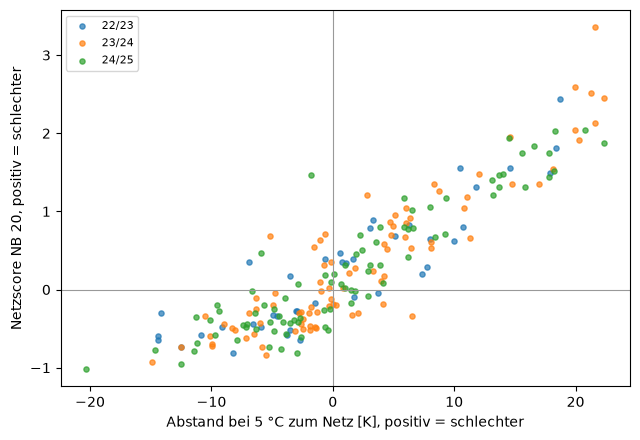

In [10]:
norm = r["norm"]
display(norm.groupby("winter").agg(Stationen=("meter", "size"),
                                   mit_Netzwert=("abstand_k", "count"),
                                   Netzmedian=("netz_median", "first"))
        .round(1))
mk = erg["markiert"][["meter", "winter", "score", "rang", "auffaellig"]]
x = norm.merge(mk, on=["meter", "winter"], suffixes=("_5c", "_netz"))
x = x.dropna(subset=["abstand_k", "score"])
zeilen = []
for winter, d in x.groupby("winter"):
    rho, p = stats.spearmanr(d["abstand_k"], d["score"])
    oben = d.nsmallest(10, "rang_5c")["auffaellig"].mean()
    zeilen.append({"winter": winter, "Stationen": len(d), "Spearman": rho,
                   "p": p, "auffällig unter den 10 schlechtesten bei 5 °C": oben})
display(pd.DataFrame(zeilen).round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for winter, d in x.groupby("winter"):
    ax.scatter(d["abstand_k"], d["score"], s=14, label=winter, alpha=0.7)
ax.axhline(0, color="0.6", lw=0.8)
ax.axvline(0, color="0.6", lw=0.8)
ax.set_xlabel("Abstand bei 5 °C zum Netz [K], positiv = schlechter")
ax.set_ylabel("Netzscore NB 20, positiv = schlechter")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
for m in (80956410, 68956372, BEISPIEL):
    n = norm[norm["meter"] == m][["winter", "norm_kwh_m3", "abstand_k", "rang",
                                  "n_stationen"]]
    s = mk[mk["meter"] == m][["winter", "score", "rang", "auffaellig"]]
    print(f"Zähler {m}")
    display(n.merge(s, on="winter", how="outer", suffixes=("_5c", "_netz"))
            .round(2))

Zähler 80956410


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,23/24,27.72,1.57,40.0,87,-0.32,63.0,False
1,24/25,9.18,17.80,6.0,84,1.74,7.0,True


Zähler 68956372


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,21/22,29.81,-1.28,25.0,43,NaN,NaN,NaN
1,22/23,28.64,-2.74,24.0,42,-0.64,38.0,False
2,23/24,3.84,22.33,1.0,87,2.45,4.0,True
3,24/25,22.49,6.23,22.0,84,0.41,32.0,False
4,25/26,17.92,NaN,NaN,4,NaN,NaN,False


Zähler 68956351


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,21/22,4.54,20.70,2.0,43,NaN,NaN,NaN
1,22/23,3.93,18.75,1.0,42,2.44,1.0,True
2,23/24,4.65,21.63,3.0,87,3.36,1.0,True
3,24/25,24.94,4.10,26.0,84,0.09,40.0,False


**9 · Zelle 2 · Einzelfälle**

- 80956410: 23/24 unauffällig (5 °C Rang 40, Netz 63), 24/25 schlecht (+17,8 K, Rang 6; Netz Rang 7, auffällig)
  --> beide sehen die Verschlechterung, Station nie begangen
- 68956372: 23/24 schlechteste bei 5 °C (+22,3 K, Rang 1; Netz Rang 4), nach Begehung 14.10.2024: Rang 22 / Netz 32
  --> beide sehen die Verbesserung
- 68956351: 21/22 Rang 2 (+20,7 K), 22/23 Rang 1, 23/24 Rang 3 (Netz jeweils 1), nach Reparatur Rang 26 (Netz 40)
  --> schon im Lernjahr (11/2021–11/2022) eine der schlechtesten --> Tagesmonitor hat den Fehler als normal gelernt


## Zusammenfassung & Bewertung

*Neu geschrieben nach der Durchsicht aller Abschnitte, Zahlen aus dem Lauf vom 24.10.2026 (NB 00, 93 HAST)*

**Worum es geht**
- läuft die Station schlechter als früher? --> jede Station gegen sich selbst, jeden Heiztag
- Gegenstück zum Netzvergleich (Station gegen alle anderen), Idee aus NB 17, ersetzt den Fensteralarm aus NB 14

**Was ins Endmodell eingeht**
- Tagesmonitor = einziger Alarmkanal im Stationsblatt
- Alarm "schlechter" in der Heizperiode (Okt–Apr) + im Netz auffällig --> Priorität hoch, nur eins davon --> mittel
- Abkühlung bei 5 °C nur als Info in der Statuszeile, DiD als Wirkungsmaß neben dem Wintervergleich

**So funktioniert er**
- Daten: nur Zählerstände (Energie, Volumen) um Mitternacht + Tagesmittel Außentemperatur
  --> 85.983 Stationstage --> 78.350 nutzbar --> 55.746 nutzbare Heiztage (Tagesmittel < 15 °C)
  --> klappt auch in der Tageswert-Phase (1 Wert/Tag um 23 Uhr reicht)
- 2 Kanäle: Abkühlung (kWh/m³ ≈ Spreizung × 1,16) und Wassermenge
- Lernjahr: erstes Jahr ab dem ersten nutzbaren Heiztag, endet spätestens 14 Tage vor der ersten Begehung
  --> 89 Stationen überwacht; 43 lernen 11/2021–11/2022, 43 erst im Winter 2023/24 (oft gekürzt durch Begehung Herbst 2024)
- CUSUM: jeden Tag + z − 0,5 aufs Konto, Alarm bei Konto > 5, mit Richtung; neuer Alarm in dieselbe Richtung erst nach Konto = 0

**Ergebnisse**
- Temperatur hilft bei der Wassermenge (Skill 0,28, bei 84 % positiv), bei der Abkühlung kaum (0,01, 54 %)
- Alarmlast: 491 Alarme bei 84 von 89 Stationen, Median 1,2 je 100 Heiztage (~2 je Heizperiode), 247 schlechter / 244 besser
- Treffertest gegen Kontrolle am selben Datum:
  - Abkühlung 22/43 (51 % gegen 27 %) --> Hebel 1,87, p = 0,001; Wassermenge Hebel 1,43, p = 0,028
  - Fenstermonitor NB 14: Hebel ≈ 1 --> zu Recht ersetzt
  - Wassermenge trifft mechanische Eingriffe (9/14, p = 0,039), Abkühlung die Einstellungen (17/29, p < 0,001)
  - Treffer kommt aus "besser" nach der Begehung, vorher keine Häufung (NB alarme) --> Erfolgskontrolle, keine Frühwarnung
- Wirkung (DiD, 30 Heiztage vor/nach, gegen Kontrolle): Abkühlung +2,2 kWh/m³ (p = 0,046), Wasser −8 % (p = 0,029), 24 Fälle
  --> mechanisch (7) am deutlichsten: +4,8 kWh/m³, −13,9 %
  --> stimmt mit dem Wintervergleich überein (Wasser-DiD vs. Steigung Spearman −0,64, p = 0,001)
  --> anders als netzvergleich B2 (ganze Winter) knapp nachweisbar
- Gegenprobe 5 °C: ordnet die Stationen fast wie der Netzscore (Spearman 0,87–0,88), von den 10 Schlechtesten 6 / 8 / 9 im Netz auffällig
- Beispiel 68956351: Reparatur am 09.09.2024 --> Alarm "besser" 2 Tage später; der Fehler selbst wurde nie gemeldet
  --> bei 5 °C schon 21/22 Rang 2 --> im Lernjahr kaputt --> als normal gelernt

**Belastbar**
- Treffertest des Abkühlungskanals (Hebel 1,87 gegen ≈ 1 beim Fenstermonitor)
- Netzscore und Abkühlung bei 5 °C finden dieselben schlechten Stationen, aus anderer Datenbasis und Methode
- DiD und Wintervergleich sind sich einig, welche Begehungen gewirkt haben
- bekannter Fall: Reparatur sofort erkannt

**Schwach**
- gelernt wird das Übliche, nicht das Gute --> Dauerfehler unsichtbar, dafür braucht es den Netzvergleich
- Abkühlungskurve ≈ Konstante --> Wetter kaum herausgerechnet --> Kälteeinbrüche lösen Alarme aus
  --> Welle 09.–12.12.2022 bei 12 von 40 Stationen, an Tagen mit ≥ 5 K Abkühlung gut doppelt so viele Verschlechterungen (8,3 % gegen 3,8 %)
  --> Tagesmittel desselben Tages, Gebäude reagieren verzögert; Wassermenge bleibt bei Kälte über dem Lernjahr am kältesten Wert stehen
- hohe Alarmlast --> ein Alarm allein ist kein Grund für eine Begehung
- Alarm = anders als im Lernjahr, nicht kaputt/repariert (68956351: 3 von 4 "besser"-Alarmen mit noch offenem Ventil)
- dauerhafte Änderung meldet nur einmal (Konto hängt am Deckel)
- nur Zählerstände: Nachtdurchfluss, Takten, Rücklauf/Vorlauf einzeln fehlen
- kleine Fallzahlen (Treffertest 43, DiD 24, mechanisch 7), Befunde aus Auto-Kodierung, Begehungen nicht zufällig (Herbst 2024)
- 2. Stationsgruppe: Lernjahr kurz und direkt vor der Begehung --> Überwachung praktisch erst danach

**Gesetzt, nicht aus den Daten hergeleitet**
- k = 0,5, h = 5, Konto-Deckel 10
- Lernjahr 365 Tage, Ende 14 Tage vor Begehung, mind. 60 Heiztage und 8 K Spanne
- Heizgrenze 15 °C, Zählerstand-Toleranz ±2 h, Wassermenge in 2-K-Klassen
- Treffer-Fenster 7 Tage vor bis 60 Tage nach dem Termin, DiD 30 Heiztage, Normtemperatur 5 °C

**Offen**
- Schwelle h festlegen (h = 8: ~1/3 weniger Alarme, Treffertest p = 0,023)
- Temperatur der letzten 2–3 Tage gemittelt oder 1 Tag verzögert; Wassermenge über die kälteste gelernte Temperatur hinaus fortschreiben
- Lernjahr nach einem bekannten Eingriff neu starten, sonst wird dieselbe Veränderung immer wieder gemeldet
- Kombination mit Dominiks LSTM-Wächter (Rücklauf, Nachtdurchfluss) auf demselben Prüfstand testen
- Abkühlung bei 5 °C funktioniert auch in 21/22 --> könnte den Netzvergleich um einen Winter verlängern
